# Лабораторная 1. Классификация растровых изображений с помощью kNN. Идентификация выбросов с помощью kNN и ODIN

**Задание 4.** Написать программу для распознавания растровых изображений, используя
метод ближайшего соседа. Реализовать программно равномерное и неравномерное
зашумление изображений и сравнить процент распознавания для используемых норм в
случаях распознавания растровых бинарных изображений и изображений в градациях
серого цвета для различных $k$. В качестве мер близости использовать предложенные в
пособии и сравнить результаты их применения.

**Задание 5.** Сгенерировать обучающую выборку для решения задачи распознавания
растровых изображений, содержащую выбросы типа 0. Назовём выбросы этого типа
выбросами типа 1, если они не распознаются как выбросы с помощью метода
ближайшего соседа, выбросами типа 2 - выбросы типа 0, которые не распознаются
с помощью метода ODIN. Реализовать оба подхода к идентификации выбросов.
Сравнить результаты их работы.

## 1. Данные

MNIST, изображения $28 \times 28$ в градациях серого (яркость от 0 до 255), 10
классов. Изображение, то есть матрица яркостей, разворачивается по строкам в
вектор признаков длины $m = 784$.

In [1]:
import os
import struct
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report

RNG = np.random.default_rng(20260905)
plt.rcParams['figure.dpi'] = 110

In [2]:
def read_idx(path):
    with open(path, 'rb') as f:
        magic, = struct.unpack('>I', f.read(4))
        dims = struct.unpack('>' + 'I' * (magic & 0xff), f.read(4 * (magic & 0xff)))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(dims)


def mnist_dir():
    candidates = [os.environ.get('MNIST_DIR'),
                  '../../bachelor/Perceptron/data_generation/MNIST/raw',
                  'data/MNIST/raw']
    for c in candidates:
        if c and Path(c, 'train-images-idx3-ubyte').exists():
            return Path(c)
    raise FileNotFoundError('не найдены файлы MNIST')


def stratified(X, y, per_class, rng):
    """Подвыборка с одинаковым числом изображений каждого класса."""
    idx = np.concatenate([rng.choice(np.flatnonzero(y == c), per_class, replace=False)
                          for c in range(10)])
    rng.shuffle(idx)
    return X[idx].copy(), y[idx].copy()


D = mnist_dir()
X_train_full = read_idx(D / 'train-images-idx3-ubyte')
y_train_full = read_idx(D / 'train-labels-idx1-ubyte')
X_test_full = read_idx(D / 't10k-images-idx3-ubyte')
y_test_full = read_idx(D / 't10k-labels-idx1-ubyte')

print(f'обучающая выборка: {X_train_full.shape}, тестовая: {X_test_full.shape}')
print(f'классы: {np.bincount(y_train_full)}')

обучающая выборка: (60000, 28, 28), тестовая: (10000, 28, 28)
классы: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


## 2. Задание 4: распознавание растровых изображений

### Теория

**Выборка.** Из MNIST берётся стратифицированная подвыборка: 2000 эталонных
(обучающих) и 300 распознаваемых (тестовых) изображений, по одинаковому числу на
класс. Для изображений в градациях серого признаки это яркости, делённые на 255.
Бинарное изображение получается порогом: пиксель равен 1, если яркость больше 128,
иначе 0.

**Метод ближайшего соседа.** Дана обучающая выборка $\{(x^{(i)}, y^{(i)})\}_{i=1}^{N}$.
Для распознаваемого вектора $x$ считаются расстояния $\rho(x, x^{(i)})$ до всех
элементов выборки, берутся $k$ ближайших, и $x$ относится к классу, который среди
них преобладает:

$$\hat y(x) = \arg\max_{c} \sum_{i \in N_k(x)} v_i \cdot [\,y^{(i)} = c\,],$$

где $N_k(x)$ это номера $k$ ближайших элементов. При $v_i \equiv 1$ это простое
голосование, при $v_i = 1/\rho(x, x^{(i)})$ взвешенное: более близкие соседи
весят больше.

**Меры близости.** Используются все расстояния, предложенные в пособии:

| Мера | Формула |
|------|---------|
| евклидово расстояние | $\sqrt{\sum_j (x_j - z_j)^2}$ |
| квадрат евклидова расстояния | $\sum_j (x_j - z_j)^2$ |
| расстояние $L_1$ | $\sum_j \lvert x_j - z_j \rvert$ |
| взвешенное евклидово расстояние | $\sqrt{\sum_j g_j (x_j - z_j)^2}$ |
| расстояние Чебышёва | $\max_j \lvert x_j - z_j \rvert$ |

Квадрат евклидова расстояния упорядочивает соседей так же, как евклидово, поэтому
при простом голосовании ответы совпадают; различаются только веса $1/\rho$ при
взвешенном голосовании. Для бинарных изображений $\lvert x_j - z_j\rvert \in \{0, 1\}$,
поэтому $L_1$ совпадает с квадратом евклидова расстояния (это число несовпадающих
пикселей), а расстояние Чебышёва принимает только значения 0 и 1.

**Веса признаков** $g_j$ для взвешенного евклидова расстояния. Пиксель важен для
распознавания, если его средняя яркость сильно меняется от класса к классу и мало
меняется внутри класса. Пусть $\bar x_{cj}$ и $s^2_{cj}$ это среднее и дисперсия
пикселя $j$ по изображениям класса $c$, $\bar x_j$ это среднее по всей выборке. Тогда

$$g_j = \frac{\frac{1}{10}\sum_c (\bar x_{cj} - \bar x_j)^2}{\frac{1}{10}\sum_c s^2_{cj} + \varepsilon},
\qquad \varepsilon = 0.01,$$

после чего веса делятся на своё среднее. Пиксели, которые на всех изображениях
равны нулю, получают вес 0. Веса считаются только по обучающей выборке.

**Зашумление.** В пособии под зашумлением понимается изменение элемента матрицы в
заданном интервале: элемент $a_{ij}$ эталона заменяется значением из
$[a_{ij} - \delta, a_{ij} + \delta]$, все элементы зашумляются одинаково, а само
изменение равномерно распределено на интервале. Это **равномерное зашумление**:

$$\tilde a_{ij} = a_{ij} + u_{ij}, \qquad u_{ij} \sim \mathrm{U}[-\delta, \delta],$$

результат обрезается до $[0, 255]$. **Неравномерное зашумление** берётся в двух
вариантах, каждый нарушает одно из условий:

- неравномерное по величине изменения: $u_{ij} \sim \mathcal{N}(0, \sigma^2)$, где
  $\sigma = 200/\sqrt3 \approx 115$, то есть дисперсия та же, что у равномерного
  шума при $\delta = 200$;
- неравномерное по элементам: шум $\mathrm{U}[-255, 255]$ добавляется только в
  квадрате $12 \times 12$ случайного положения, остальные пиксели не меняются.

Шум добавляется к изображению в градациях серого, бинарное изображение
получается из зашумлённого тем же порогом 128. Поэтому при $\delta = 100$ фон
(яркость 0) и штрихи (яркость около 255) после бинаризации не меняются, и шум
остаётся только на краях штрихов.

**Что перебирается**

| Параметр | Значения |
|---|---|
| представление | градации серого, бинарное |
| зашумление | нет; равномерное $\delta = 100$ и $\delta = 200$; нормальное $\sigma = 115$; блок $12 \times 12$ |
| мера близости | евклидово, квадрат евклидова, $L_1$, взвешенное евклидово, Чебышёва |
| $k$ | 1, 3, 5, 7, 9 |
| голосование | простое, взвешенное |

**Мера качества.** Доля верно распознанных изображений
$\mathrm{accuracy} = \frac1n \sum_k [\,\hat y_k = y_k\,]$, процент распознавания
равен $100 \cdot \mathrm{accuracy}$.

подвыборка: обучающая (2000, 28, 28), тестовая (300, 28, 28)
по классам: [200 200 200 200 200 200 200 200 200 200]


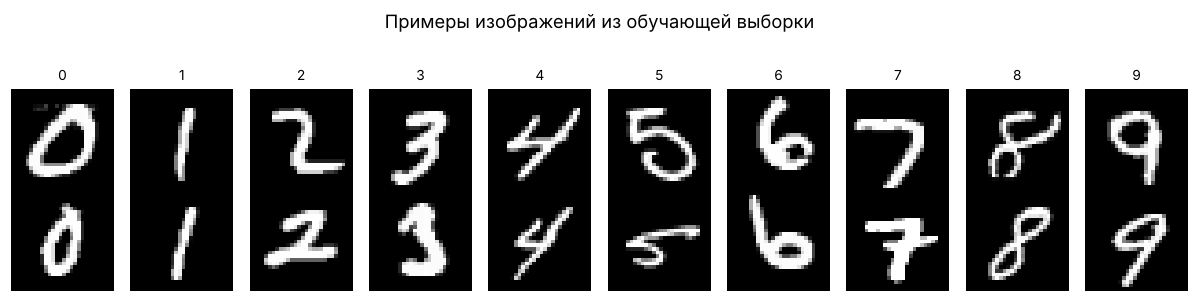

In [3]:
X_tr, y_tr = stratified(X_train_full, y_train_full, 200, RNG)
X_te, y_te = stratified(X_test_full, y_test_full, 30, RNG)
print(f'подвыборка: обучающая {X_tr.shape}, тестовая {X_te.shape}')
print(f'по классам: {np.bincount(y_tr)}')

fig, axes = plt.subplots(2, 10, figsize=(11, 2.6))
for c in range(10):
    for row in range(2):
        j = np.flatnonzero(y_tr == c)[row]
        axes[row, c].imshow(X_tr[j], cmap='gray')
        axes[row, c].axis('off')
    axes[0, c].set_title(str(c), fontsize=9)
fig.suptitle('Примеры изображений из обучающей выборки', y=1.04)
plt.tight_layout()
plt.show()

### Реализация метода ближайшего соседа

In [4]:
def point_distances(x, B, metric, g=None):
    """Расстояния от вектора x до каждой строки матрицы B."""
    # x - B: из x вычитается каждая строка B, получается матрица разностей
    # той же формы, что B, и дальше по её строкам берётся нужная норма
    diff = x - B
    if metric == 'l2':
        return np.sqrt((diff ** 2).sum(axis=1))
    if metric == 'l2sq':
        return (diff ** 2).sum(axis=1)
    if metric == 'l1':
        return np.abs(diff).sum(axis=1)
    if metric == 'wl2':
        # g умножается на каждую строку квадратов разностей, то есть пиксель j на g_j
        return np.sqrt((g * diff ** 2).sum(axis=1))
    if metric == 'linf':
        return np.abs(diff).max(axis=1)
    raise ValueError(metric)


def distances(A, B, metric, g=None):
    """Матрица расстояний: в строке i расстояния от запроса A[i] до всех объектов B."""
    out = np.empty((len(A), len(B)), dtype=np.float32)
    for i in range(len(A)):
        out[i] = point_distances(A[i], B, metric, g)
    return out


def knn_predict(dist, y_train, k, weighted):
    """Предсказание по готовой матрице расстояний."""
    pred = np.zeros(len(dist), dtype=int)
    for i in range(len(dist)):
        nn = np.argsort(dist[i])[:k]  # номера k ближайших объектов обучающей выборки
        votes = np.zeros(10)
        for j in nn:
            # 1e-9 страхует от нулевого расстояния при совпадении изображений
            v = 1.0 / (dist[i, j] + 1e-9) if weighted else 1.0
            votes[y_train[j]] += v
        pred[i] = votes.argmax()
    return pred


def pixel_weights(F, y, eps=0.01):
    """Веса пикселей: разброс средних по классам, делённый на разброс внутри классов."""
    means = np.array([F[y == c].mean(axis=0) for c in range(10)])  # строка c - средний вектор класса c
    variances = np.array([F[y == c].var(axis=0) for c in range(10)])
    between = ((means - F.mean(axis=0)) ** 2).mean(axis=0)
    within = variances.mean(axis=0)
    g = between / (within + eps)
    return g / g.mean()


def features(X):
    """Изображения в векторы длины 784 со значениями от 0 до 1."""
    return X.reshape(len(X), -1).astype(np.float32) / 255.0


def binarize(X, threshold=128):
    return (X > threshold).astype(np.uint8) * 255

совпадение с sklearn: 1.0000
accuracy собственной реализации: 0.8867


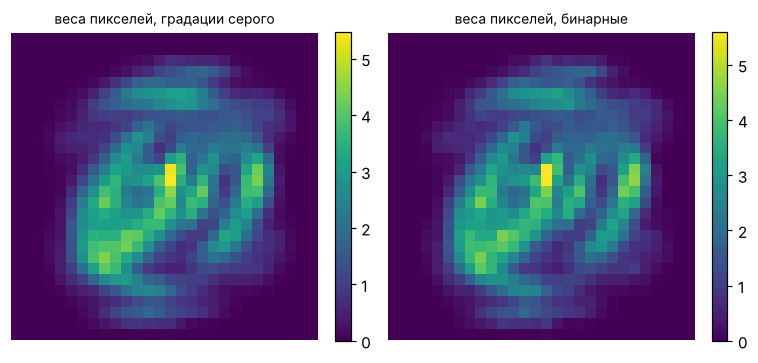

пикселей с нулевым весом: 149 из 784


In [5]:
flat_tr, flat_te = features(X_tr), features(X_te)

mine = knn_predict(distances(flat_te, flat_tr, 'l2'), y_tr, k=5, weighted=False)
ref = KNeighborsClassifier(n_neighbors=5, metric='euclidean').fit(flat_tr, y_tr).predict(flat_te)
print(f'совпадение с sklearn: {np.mean(mine == ref):.4f}')
print(f'accuracy собственной реализации: {np.mean(mine == y_te):.4f}')

G_GRAY = pixel_weights(flat_tr, y_tr)
G_BIN = pixel_weights(features(binarize(X_tr)), y_tr)
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
for ax, g, name in zip(axes, [G_GRAY, G_BIN], ['градации серого', 'бинарные']):
    im = ax.imshow(g.reshape(28, 28), cmap='viridis')
    ax.set_title(f'веса пикселей, {name}', fontsize=9)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()
print(f'пикселей с нулевым весом: {np.sum(G_GRAY == 0)} из 784')

### Зашумление

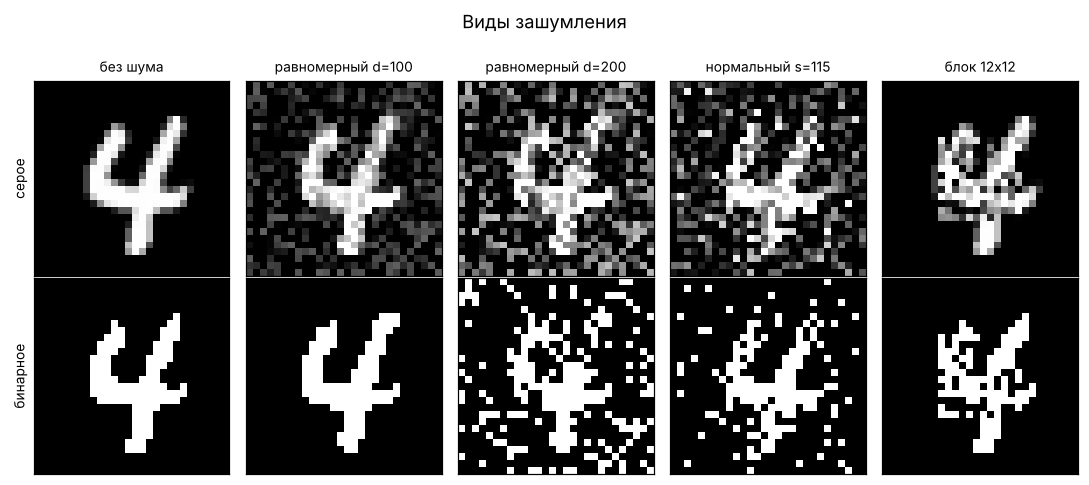

доля изменённых пикселей:
                         серое  бинарное
  без шума               0.000     0.000
  равномерный d=100      0.588     0.020
  равномерный d=200      0.590     0.196
  нормальный s=115       0.590     0.150
  блок 12x12             0.123     0.050


In [6]:
def uniform_noise(X, delta, rng):
    """Равномерное: к каждому пикселю прибавляется U[-delta, delta]."""
    noisy = X + rng.uniform(-delta, delta, X.shape)
    return np.clip(np.round(noisy), 0, 255).astype(np.uint8)


def normal_noise(X, sigma, rng):
    """Неравномерное по величине: к каждому пикселю прибавляется N(0, sigma^2)."""
    noisy = X + rng.normal(0, sigma, X.shape)
    return np.clip(np.round(noisy), 0, 255).astype(np.uint8)


def block_noise(X, size, rng):
    """Неравномерное по элементам: шум U[-255, 255] только в квадрате size x size."""
    noisy = X.astype(float)
    n, h, w = X.shape
    for i in range(n):
        r0 = rng.integers(0, h - size + 1)
        c0 = rng.integers(0, w - size + 1)
        noisy[i, r0:r0 + size, c0:c0 + size] += rng.uniform(-255, 255, (size, size))
    return np.clip(np.round(noisy), 0, 255).astype(np.uint8)


conditions = {
    'без шума': lambda X, rng: X.copy(),
    'равномерный d=100': lambda X, rng: uniform_noise(X, 100, rng),
    'равномерный d=200': lambda X, rng: uniform_noise(X, 200, rng),
    'нормальный s=115': lambda X, rng: normal_noise(X, 200 / np.sqrt(3), rng),
    'блок 12x12': lambda X, rng: block_noise(X, 12, rng),
}

fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for col, (name, f) in enumerate(conditions.items()):
    noisy = f(X_te[:1], np.random.default_rng(1))[0]
    axes[0, col].imshow(noisy, cmap='gray', vmin=0, vmax=255)
    axes[1, col].imshow(binarize(noisy), cmap='gray', vmin=0, vmax=255)
    axes[0, col].set_title(name, fontsize=9)
    for row in range(2):
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
axes[0, 0].set_ylabel('серое', fontsize=9)
axes[1, 0].set_ylabel('бинарное', fontsize=9)
fig.suptitle('Виды зашумления', y=1.0)
plt.tight_layout()
plt.show()

print('доля изменённых пикселей:')
print(f'  {"":20s} {"серое":>7s} {"бинарное":>9s}')
for name, f in conditions.items():
    noisy = f(X_te, np.random.default_rng(1))
    print(f'  {name:20s} {np.mean(noisy != X_te):7.3f} '
          f'{np.mean(binarize(noisy) != binarize(X_te)):9.3f}')

### Эксперименты

In [7]:
METRICS = ['l2', 'l2sq', 'l1', 'wl2', 'linf']
KS = [1, 3, 5, 7, 9]

rows = []
for repr_name, prep, g in [('серое', lambda X: X, G_GRAY), ('бинарное', binarize, G_BIN)]:
    train = features(prep(X_tr))
    for cond_name, noise in conditions.items():
        noisy = noise(X_te, np.random.default_rng(20260905))
        test = features(prep(noisy))
        for metric in METRICS:
            dist = distances(test, train, metric, g)
            for k in KS:
                for weighted in (False, True):
                    pred = knn_predict(dist, y_tr, k, weighted)
                    rows.append(dict(representation=repr_name, condition=cond_name,
                                     metric=metric, k=k, weighted=weighted,
                                     accuracy=float(np.mean(pred == y_te))))

df = pd.DataFrame(rows)
df.to_csv('results_knn.csv', index=False)
print(f'{len(df)} конфигураций')

500 конфигураций


### Результаты

Меры близости на изображениях без шума, простое голосование:

In [8]:
clean = df[(df.condition == 'без шума') & (~df.weighted)]
pivot = clean.pivot_table(index=['representation', 'metric'], columns='k', values='accuracy')
print(pivot.round(3).to_string())

k                          1      3      5      7      9
representation metric                                   
бинарное       l1      0.880  0.890  0.900  0.883  0.873
               l2      0.880  0.890  0.900  0.883  0.873
               l2sq    0.880  0.890  0.900  0.883  0.873
               linf    0.100  0.100  0.100  0.100  0.100
               wl2     0.887  0.893  0.887  0.873  0.870
серое          l1      0.900  0.883  0.877  0.880  0.873
               l2      0.930  0.907  0.887  0.893  0.873
               l2sq    0.930  0.907  0.887  0.893  0.873
               linf    0.567  0.527  0.550  0.540  0.560
               wl2     0.907  0.903  0.907  0.880  0.880


Устойчивость мер близости к шуму: лучшая по $k$ доля верных ответов, простое
голосование:

In [9]:
order = list(conditions.keys())
best_k = df[~df.weighted].groupby(['representation', 'condition', 'metric'])['accuracy'].max()
table = best_k.unstack('metric')[METRICS]
table = table.reindex(pd.MultiIndex.from_product([['серое', 'бинарное'], order]))
print(table.round(3).to_string())

metric                         l2   l2sq     l1    wl2   linf
серое    без шума           0.930  0.930  0.900  0.907  0.567
         равномерный d=100  0.927  0.927  0.913  0.913  0.517
         равномерный d=200  0.893  0.893  0.893  0.887  0.383
         нормальный s=115   0.893  0.893  0.877  0.883  0.100
         блок 12x12         0.903  0.903  0.887  0.910  0.533
бинарное без шума           0.900  0.900  0.900  0.893  0.100
         равномерный d=100  0.893  0.893  0.893  0.883  0.100
         равномерный d=200  0.847  0.847  0.847  0.853  0.100
         нормальный s=115   0.863  0.863  0.863  0.860  0.100
         блок 12x12         0.873  0.873  0.873  0.867  0.100


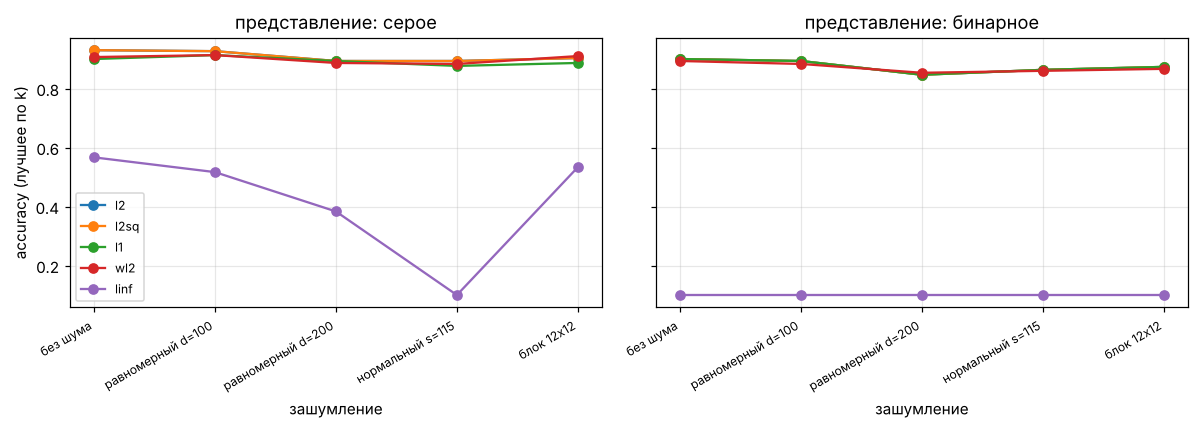

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, repr_name in zip(axes, ['серое', 'бинарное']):
    sub = df[(df.representation == repr_name) & (~df.weighted)]
    for metric in METRICS:
        acc = [sub[(sub.condition == c) & (sub.metric == metric)].accuracy.max() for c in order]
        ax.plot(range(len(order)), acc, marker='o', label=metric)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=30, ha='right', fontsize=8)
    ax.set_title(f'представление: {repr_name}')
    ax.set_xlabel('зашумление')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('accuracy (лучшее по k)')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Зависимость от $k$, изображения в градациях серого:

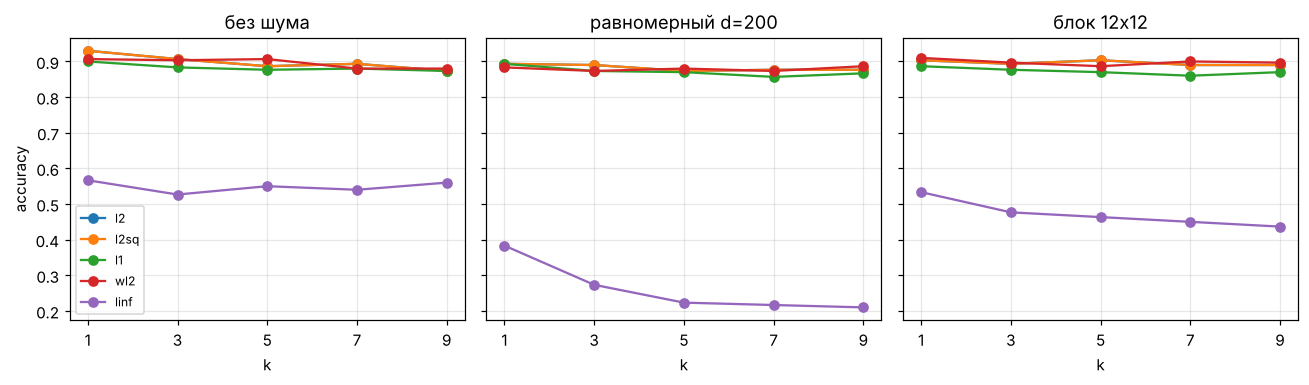

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, cond in zip(axes, ['без шума', 'равномерный d=200', 'блок 12x12']):
    sub = df[(df.representation == 'серое') & (df.condition == cond) & (~df.weighted)]
    for metric in METRICS:
        s = sub[sub.metric == metric].sort_values('k')
        ax.plot(s.k, s.accuracy, marker='o', label=metric)
    ax.set_title(cond)
    ax.set_xlabel('k')
    ax.set_xticks(KS)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('accuracy')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Взвешенное голосование: прирост доли верных ответов относительно простого
голосования, среднее по представлениям, зашумлениям и $k > 1$:

In [12]:
cmp = df.pivot_table(index=['representation', 'condition', 'metric', 'k'],
                     columns='weighted', values='accuracy')
cmp['прирост'] = cmp[True] - cmp[False]
gain = cmp[cmp.index.get_level_values('k') > 1].groupby('metric')['прирост'].agg(['mean', 'max'])
print(gain.loc[METRICS].round(4).to_string())

          mean     max
metric                
l2      0.0083  0.0200
l2sq    0.0084  0.0200
l1      0.0086  0.0200
wl2     0.0075  0.0167
linf    0.0045  0.0400


лучшая конфигурация без шума: серое, l2, k = 1, взвешенное голосование: нет, accuracy 0.930


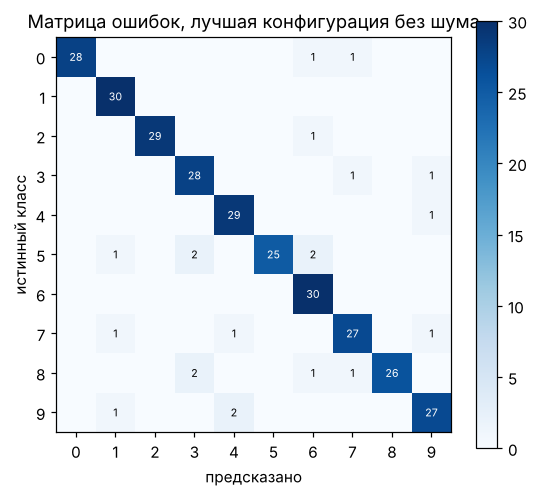

              precision    recall  f1-score   support

           0      1.000     0.933     0.966        30
           1      0.909     1.000     0.952        30
           2      1.000     0.967     0.983        30
           3      0.875     0.933     0.903        30
           4      0.906     0.967     0.935        30
           5      1.000     0.833     0.909        30
           6      0.857     1.000     0.923        30
           7      0.900     0.900     0.900        30
           8      1.000     0.867     0.929        30
           9      0.900     0.900     0.900        30

    accuracy                          0.930       300
   macro avg      0.935     0.930     0.930       300
weighted avg      0.935     0.930     0.930       300



In [13]:
best = df.loc[df[df.condition == 'без шума'].accuracy.idxmax()]
print(f'лучшая конфигурация без шума: {best.representation}, {best.metric}, k = {best.k}, '
      f'взвешенное голосование: {"да" if best.weighted else "нет"}, '
      f'accuracy {best.accuracy:.3f}')

prep, g = (lambda X: X, G_GRAY) if best.representation == 'серое' else (binarize, G_BIN)
pred = knn_predict(distances(features(prep(X_te)), features(prep(X_tr)), best.metric, g),
                   y_tr, int(best.k), bool(best.weighted))

cm = confusion_matrix(y_te, pred)
fig, ax = plt.subplots(figsize=(5.2, 4.6))
im = ax.imshow(cm, cmap='Blues')
ax.set_xlabel('предсказано')
ax.set_ylabel('истинный класс')
ax.set_title('Матрица ошибок, лучшая конфигурация без шума')
ax.set_xticks(range(10)); ax.set_yticks(range(10))
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7,
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.colorbar(im)
plt.tight_layout()
plt.show()

print(classification_report(y_te, pred, digits=3))

## 3. Задание 5: идентификация выбросов

### Теория

**Выборка.** Берётся стратифицированная подвыборка из 1800 изображений MNIST, в неё
вносятся выбросы трёх видов по 60 штук каждого: перепутанная метка (изображение не
тронуто, метка заменена на случайную чужую), сильная порча ($60\%$ пикселей
заменены случайными значениями, метка верна), поворот на 180 градусов (метка
исходная). Чистые изображения берутся из первой половины обучающей выборки MNIST,
выбросы делаются из второй, поэтому точных копий выбросов среди чистых нет.

**Выброс** это элемент выборки, который метод ближайшего соседа классифицирует
неправильно по остальным элементам выборки: ближайшими к нему оказываются
объекты чужих классов.

| Тип | Что это |
|-----|---------|
| 0 | выбросы, внесённые в выборку намеренно, для них известна истина |
| 1 | выбросы типа 0, которые не обнаружил метод ближайшего соседа |
| 2 | выбросы типа 0, которые не обнаружил ODIN |

**Метод ближайшего соседа.** Для элемента $x^{(i)}$ берутся $k$ ближайших к нему
элементов выборки, кроме него самого, и преобладающая среди них метка. Если она не
совпадает с $y^{(i)}$, элемент помечается выбросом.

**ODIN** (Outlier Detection using Indegree Number) меток не использует. По выборке
строится граф $k$ ближайших соседей: ребро $i \to j$ проводится, если $x^{(j)}$
входит в число $k$ ближайших к $x^{(i)}$. Отношение "быть среди $k$ ближайших"
несимметрично, поэтому граф можно рассматривать двумя способами:

- ориентированный: степень вершины это число входящих рёбер
  $\deg^{-}(j) = \lvert\{\, i : j \in N_k(i) \,\}\rvert$, то есть для скольких
  элементов $x^{(j)}$ оказался соседом;
- неориентированный: $i$ и $j$ соединены, если хотя бы один из них среди $k$
  ближайших к другому; степень вершины не меньше $k$.

Элемент помечается выбросом, если степень его вершины меньше порога $T$.

**Мера близости** - евклидово расстояние между векторами яркостей, значения
пикселей поделены на 255.

**Что перебирается**

| Параметр | Значения |
|---|---|
| $k$, оба метода | 1, 3, 5, 7, 9, 11, 15, 20 |
| порог $T$, ODIN, ориентированный граф | от 0 до $\min(k, 6)$ |
| порог $T$, ODIN, неориентированный граф | от $k$ до $k + 6$ |

**Меры качества**

$$\text{precision} = \frac{TP}{TP + FP}, \qquad
\text{recall} = \frac{TP}{TP + FN}, \qquad
F_1 = \frac{2\,\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}},$$

где $TP$ это верно помеченные выбросы, $FP$ помеченные чистые элементы,
$FN$ пропущенные выбросы.

In [14]:
RNG2 = np.random.default_rng(20260905)

# чистые изображения из первой половины MNIST, выбросы потом делаются из второй
X_clean, y_clean = stratified(X_train_full[:30000], y_train_full[:30000], 180, RNG2)
print(f'чистая выборка: {X_clean.shape}, по классам {np.bincount(y_clean)}')

N_OUT = 60


def make_outliers(X_pool, y_pool, rng):
    """Три вида выбросов по N_OUT штук: чужая метка, порча пикселей, поворот."""
    parts, labels, kinds = [], [], []

    idx = rng.choice(len(X_pool), N_OUT, replace=False)
    # прибавление случайного числа от 1 до 9 по модулю 10 даёт заведомо чужую метку
    wrong = (y_pool[idx] + rng.integers(1, 10, N_OUT)) % 10
    parts.append(X_pool[idx].copy()); labels.append(wrong)
    kinds += ['перепутанная метка'] * N_OUT

    idx = rng.choice(len(X_pool), N_OUT, replace=False)
    img = X_pool[idx].copy()
    mask = rng.random(img.shape) < 0.6
    img[mask] = rng.integers(0, 256, mask.sum(), dtype=np.uint8)
    parts.append(img); labels.append(y_pool[idx].copy())
    kinds += ['сильная порча'] * N_OUT

    idx = rng.choice(len(X_pool), N_OUT, replace=False)
    # [::-1, ::-1] переворачивает изображение по обеим осям, это поворот на 180
    parts.append(X_pool[idx][:, ::-1, ::-1].copy()); labels.append(y_pool[idx].copy())
    kinds += ['поворот 180'] * N_OUT

    return np.concatenate(parts), np.concatenate(labels), np.array(kinds)


pool_X, pool_y = stratified(X_train_full[30000:], y_train_full[30000:], 400,
                            np.random.default_rng(7))
X_out, y_out, kind_out = make_outliers(pool_X, pool_y, RNG2)

X = np.concatenate([X_clean, X_out])
y = np.concatenate([y_clean, y_out])
kind = np.array(['чистый'] * len(X_clean) + list(kind_out))
is_outlier = kind != 'чистый'

perm = RNG2.permutation(len(X))
X, y, kind, is_outlier = X[perm], y[perm], kind[perm], is_outlier[perm]

print(f'выборка: {len(X)} элементов, выбросов типа 0: {is_outlier.sum()} '
      f'({is_outlier.mean():.1%})')
print(pd.Series(kind).value_counts().to_string())

чистая выборка: (1800, 28, 28), по классам [180 180 180 180 180 180 180 180 180 180]
выборка: 1980 элементов, выбросов типа 0: 180 (9.1%)
чистый                1800
поворот 180             60
сильная порча           60
перепутанная метка      60


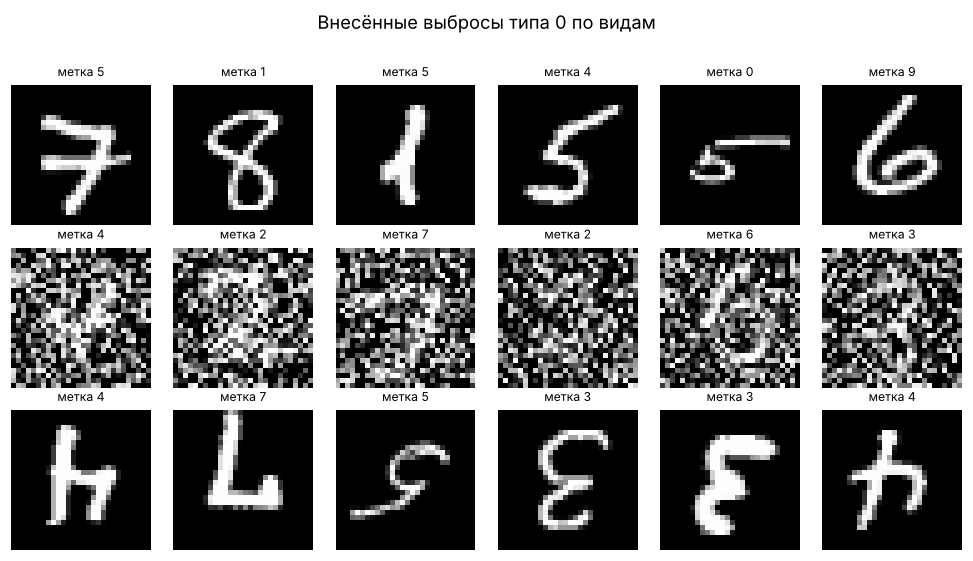

In [15]:
fig, axes = plt.subplots(3, 6, figsize=(9, 5))
for row, k in enumerate(['перепутанная метка', 'сильная порча', 'поворот 180']):
    idx = np.flatnonzero(kind == k)[:6]
    for col, j in enumerate(idx):
        axes[row, col].imshow(X[j], cmap='gray')
        axes[row, col].set_title(f'метка {y[j]}', fontsize=8)
        axes[row, col].axis('off')
    axes[row, 0].set_ylabel(k, fontsize=8)
fig.suptitle('Внесённые выбросы типа 0 по видам', y=1.01)
plt.tight_layout()
plt.show()

### Реализация методов

In [16]:
def pair_distances(X):
    """Матрица попарных евклидовых расстояний между изображениями выборки."""
    A = features(X)
    d = np.empty((len(A), len(A)), dtype=np.float32)
    for i in range(len(A)):
        # A - A[i] вычитает i-е изображение из каждой строки, дальше норма по строкам
        d[i] = np.sqrt(((A - A[i]) ** 2).sum(axis=1))
    np.fill_diagonal(d, np.inf)  # элемент не может быть соседом самому себе
    return d


def knn_flag(dist, y, k):
    """Выброс, если преобладающая метка k ближайших соседей не совпадает со своей."""
    flag = np.zeros(len(dist), dtype=bool)
    for i in range(len(dist)):
        nn = np.argsort(dist[i])[:k]  # номера k ближайших к i-му элементу
        votes = np.bincount(y[nn], minlength=10)  # сколько соседей у каждого класса
        flag[i] = votes.argmax() != y[i]
    return flag


def knn_graph(dist, k):
    """Матрица смежности графа k ближайших соседей: A[i, j] = True, если j среди k ближайших к i."""
    A = np.zeros(dist.shape, dtype=bool)
    for i in range(len(dist)):
        A[i, np.argsort(dist[i])[:k]] = True
    return A


def odin_degree(dist, k, directed=True):
    """Степени вершин: входящие для ориентированного графа, обычные для неориентированного."""
    A = knn_graph(dist, k)
    if directed:
        return A.sum(axis=0)  # сумма по столбцу j это число рёбер, входящих в j
    # A.T это рёбра в обратную сторону; ребро есть, если оно есть хотя бы в одну сторону
    return (A | A.T).sum(axis=1)


dist = pair_distances(X)
print(f'матрица расстояний {dist.shape}')

матрица расстояний (1980, 1980)


### Подбор параметров

In [17]:
def scores(flag, truth):
    """precision, recall и F1 для булева признака flag против истины truth."""
    tp = int((flag & truth).sum())
    fp = int((flag & ~truth).sum())
    fn = int((~flag & truth).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1


rows = []
for k in [1, 3, 5, 7, 9, 11, 15, 20]:
    p, r, f = scores(knn_flag(dist, y, k), is_outlier)
    rows.append(dict(method='kNN', k=k, threshold=np.nan, precision=p, recall=r, f1=f))
    deg_in = odin_degree(dist, k, directed=True)
    for T in range(0, min(k, 6) + 1):
        p, r, f = scores(deg_in < T, is_outlier)
        rows.append(dict(method='ODIN, ориент.', k=k, threshold=T,
                         precision=p, recall=r, f1=f))
    deg_un = odin_degree(dist, k, directed=False)
    for T in range(k, k + 7):
        p, r, f = scores(deg_un < T, is_outlier)
        rows.append(dict(method='ODIN, неориент.', k=k, threshold=T,
                         precision=p, recall=r, f1=f))

res = pd.DataFrame(rows)
res.to_csv('results_outliers.csv', index=False)
print(f'{len(res)} конфигураций')
print(res[res.method == 'kNN'].round(3).to_string(index=False))

111 конфигураций
method  k  threshold  precision  recall    f1
   kNN  1        NaN      0.331   0.594 0.425
   kNN  3        NaN      0.373   0.589 0.457
   kNN  5        NaN      0.368   0.572 0.448
   kNN  7        NaN      0.369   0.617 0.462
   kNN  9        NaN      0.349   0.611 0.444
   kNN 11        NaN      0.344   0.622 0.443
   kNN 15        NaN      0.327   0.611 0.426
   kNN 20        NaN      0.323   0.622 0.425


In [18]:
for m in ['ODIN, ориент.', 'ODIN, неориент.']:
    print(f'{m}, лучшие по F1:')
    print(res[res.method == m].sort_values('f1', ascending=False).head(5)
          .round(3).to_string(index=False))
    print()

ODIN, ориент., лучшие по F1:
       method  k  threshold  precision  recall    f1
ODIN, ориент. 20        5.0      0.444   0.417 0.430
ODIN, ориент. 20        6.0      0.377   0.467 0.417
ODIN, ориент. 20        4.0      0.488   0.350 0.408
ODIN, ориент. 15        4.0      0.387   0.417 0.401
ODIN, ориент.  9        3.0      0.325   0.517 0.399

ODIN, неориент., лучшие по F1:
         method  k  threshold  precision  recall    f1
ODIN, неориент. 20       23.0      0.205   0.494 0.289
ODIN, неориент. 15       18.0      0.192   0.589 0.289
ODIN, неориент. 20       24.0      0.189   0.594 0.287
ODIN, неориент. 15       17.0      0.208   0.439 0.283
ODIN, неориент.  7        8.0      0.204   0.422 0.275



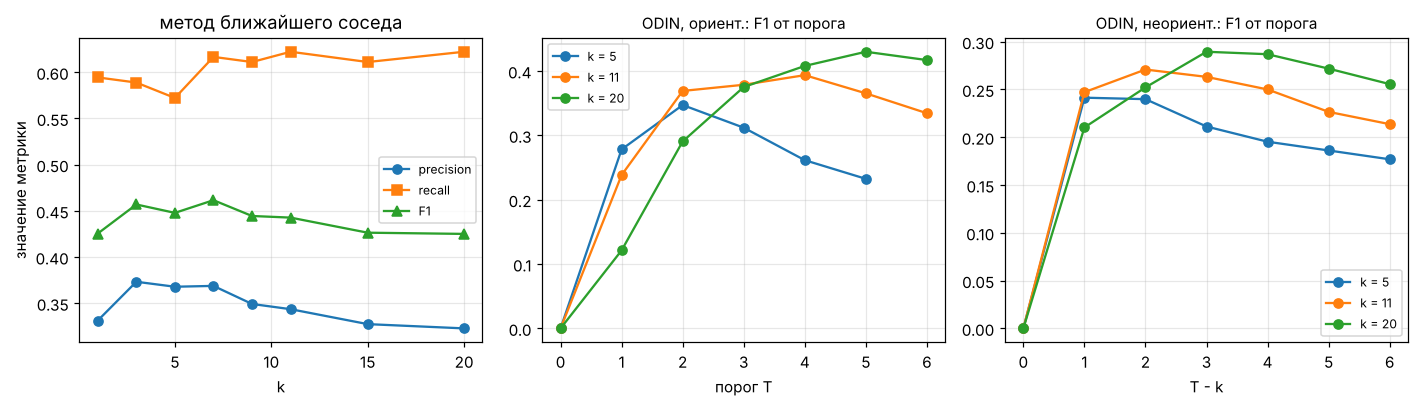

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
sub = res[res.method == 'kNN']
axes[0].plot(sub.k, sub.precision, marker='o', label='precision')
axes[0].plot(sub.k, sub.recall, marker='s', label='recall')
axes[0].plot(sub.k, sub.f1, marker='^', label='F1')
axes[0].set_title('метод ближайшего соседа')
axes[0].set_xlabel('k'); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)

for ax, m, shift in [(axes[1], 'ODIN, ориент.', False), (axes[2], 'ODIN, неориент.', True)]:
    for k in [5, 11, 20]:
        s = res[(res.method == m) & (res.k == k)].sort_values('threshold')
        # для неориентированного графа порог откладывается от k
        ax.plot(s.threshold - (k if shift else 0), s.f1, marker='o', label=f'k = {k}')
    ax.set_title(f'{m}: F1 от порога', fontsize=10)
    ax.set_xlabel('T - k' if shift else 'порог T')
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel('значение метрики')
plt.tight_layout()
plt.show()

### Выбросы типа 1 и типа 2

Для ODIN здесь берётся ориентированный граф, как в определении метода, с лучшими
по $F_1$ параметрами.

In [20]:
K_KNN = int(res[res.method == 'kNN'].sort_values('f1').iloc[-1].k)
best_o = res[res.method == 'ODIN, ориент.'].sort_values('f1').iloc[-1]
K_ODIN, T_ODIN = int(best_o.k), int(best_o.threshold)
print(f'выбраны параметры: kNN k = {K_KNN}; ODIN k = {K_ODIN}, T = {T_ODIN}')

flag_knn = knn_flag(dist, y, K_KNN)
flag_odin = odin_degree(dist, K_ODIN) < T_ODIN

type1 = is_outlier & ~flag_knn
type2 = is_outlier & ~flag_odin

print(f'выбросов типа 0: {is_outlier.sum()}')
print(f'выбросов типа 1 (пропустил kNN):  {type1.sum()} ({type1.sum() / is_outlier.sum():.1%})')
print(f'выбросов типа 2 (пропустил ODIN): {type2.sum()} ({type2.sum() / is_outlier.sum():.1%})')
print(f'пропущены обоими: {(type1 & type2).sum()}')
print(f'пойманы обоими:   {(flag_knn & flag_odin & is_outlier).sum()}')

выбраны параметры: kNN k = 7; ODIN k = 20, T = 5
выбросов типа 0: 180
выбросов типа 1 (пропустил kNN):  69 (38.3%)
выбросов типа 2 (пропустил ODIN): 105 (58.3%)
пропущены обоими: 19
пойманы обоими:   25


                    всего  поймал kNN  поймал ODIN  тип 1  тип 2
перепутанная метка     60          59            6      1     54
поворот 180            60          43           18     17     42
сильная порча          60           9           51     51      9


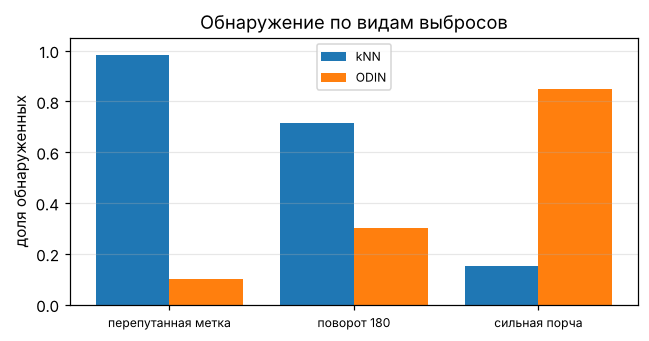

In [21]:
by_kind = pd.DataFrame({
    'всего': pd.Series(kind[is_outlier]).value_counts(),
    'поймал kNN': pd.Series(kind[is_outlier & flag_knn]).value_counts(),
    'поймал ODIN': pd.Series(kind[is_outlier & flag_odin]).value_counts(),
}).fillna(0).astype(int)
by_kind['тип 1'] = by_kind['всего'] - by_kind['поймал kNN']
by_kind['тип 2'] = by_kind['всего'] - by_kind['поймал ODIN']
print(by_kind.to_string())

fig, ax = plt.subplots(figsize=(6, 3.2))
labels = list(by_kind.index)
xs = np.arange(len(labels))
ax.bar(xs - 0.2, by_kind['поймал kNN'] / by_kind['всего'], 0.4, label='kNN')
ax.bar(xs + 0.2, by_kind['поймал ODIN'] / by_kind['всего'], 0.4, label='ODIN')
ax.set_xticks(xs); ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel('доля обнаруженных'); ax.set_ylim(0, 1.05)
ax.set_title('Обнаружение по видам выбросов'); ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

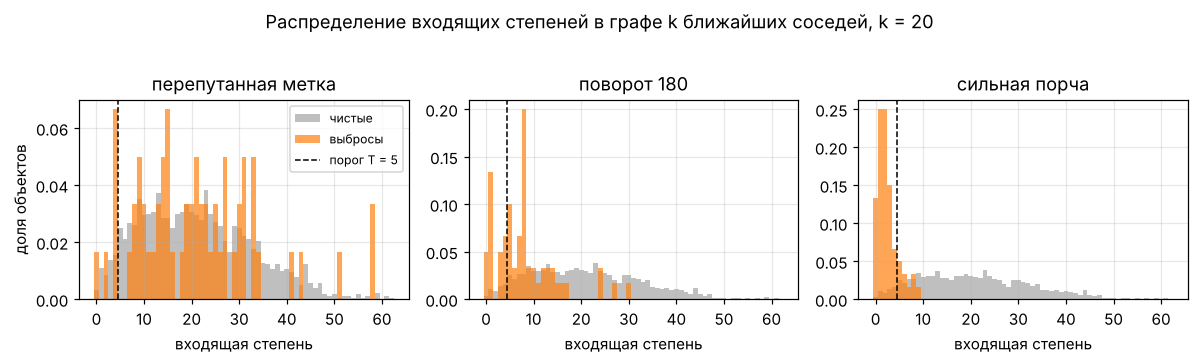

In [22]:
ind = odin_degree(dist, K_ODIN)
# границы на полуцелых: каждое целое значение степени попадает в свой столбик
bins = np.arange(0, ind.max() + 2) - 0.5
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharex=True)
for ax, name in zip(axes, ['перепутанная метка', 'поворот 180', 'сильная порча']):
    # при ширине столбика 1 density=True даёт долю объектов своей группы
    ax.hist(ind[kind == 'чистый'], bins=bins, density=True, color='gray', alpha=0.5, label='чистые')
    ax.hist(ind[kind == name], bins=bins, density=True, color='C1', alpha=0.7, label='выбросы')
    ax.axvline(T_ODIN - 0.5, color='black', ls='--', lw=1, label=f'порог T = {T_ODIN}')
    ax.set_title(name)
    ax.set_xlabel('входящая степень')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('доля объектов')
axes[0].legend(fontsize=8)
fig.suptitle(f'Распределение входящих степеней в графе k ближайших соседей, k = {K_ODIN}', y=1.02)
plt.tight_layout()
plt.show()

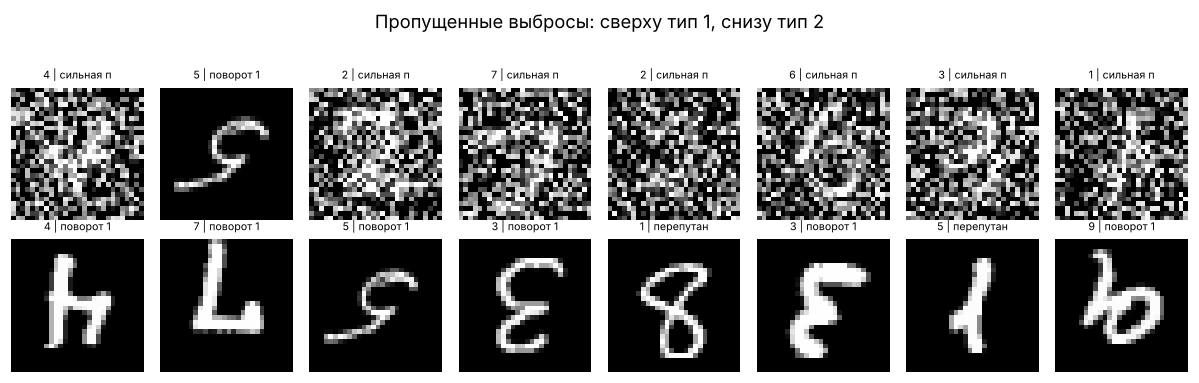

In [23]:
fig, axes = plt.subplots(2, 8, figsize=(11, 3.4))
for row, (mask, name) in enumerate([(type1, 'тип 1: пропустил kNN'),
                                    (type2, 'тип 2: пропустил ODIN')]):
    idx = np.flatnonzero(mask)[:8]
    for col in range(8):
        ax = axes[row, col]
        ax.axis('off')
        if col < len(idx):
            j = idx[col]
            ax.imshow(X[j], cmap='gray')
            ax.set_title(f'{y[j]} | {kind[j][:9]}', fontsize=7)
    axes[row, 0].set_ylabel(name, fontsize=8)
fig.suptitle('Пропущенные выбросы: сверху тип 1, снизу тип 2', y=1.03)
plt.tight_layout()
plt.show()

### Сравнение методов

In [24]:
best_u = res[res.method == 'ODIN, неориент.'].sort_values('f1').iloc[-1]
flag_odin_u = odin_degree(dist, int(best_u.k), directed=False) < int(best_u.threshold)

both = flag_knn & flag_odin
table = pd.DataFrame({
    'выбросы типа 0': [int((both & is_outlier).sum()), int((flag_knn & ~flag_odin & is_outlier).sum()),
                       int((flag_odin & ~flag_knn & is_outlier).sum()),
                       int((~flag_knn & ~flag_odin & is_outlier).sum())],
    'чистые': [int((both & ~is_outlier).sum()), int((flag_knn & ~flag_odin & ~is_outlier).sum()),
               int((flag_odin & ~flag_knn & ~is_outlier).sum()),
               int((~flag_knn & ~flag_odin & ~is_outlier).sum())],
}, index=['помечены обоими', 'только kNN', 'только ODIN', 'не помечены'])
print(table.to_string())
print()
for name, flag in [('kNN', flag_knn), ('ODIN, ориентированный', flag_odin),
                   ('ODIN, неориентированный', flag_odin_u),
                   ('kNN или ODIN', flag_knn | flag_odin),
                   ('kNN и ODIN', flag_knn & flag_odin)]:
    p, r, f = scores(flag, is_outlier)
    print(f'{name:24s} precision={p:.3f}  recall={r:.3f}  F1={f:.3f}  '
          f'помечено {int(flag.sum())}')

                 выбросы типа 0  чистые
помечены обоими              25      31
только kNN                   86     159
только ODIN                  50      63
не помечены                  19    1547

kNN                      precision=0.369  recall=0.617  F1=0.462  помечено 301
ODIN, ориентированный    precision=0.444  recall=0.417  F1=0.430  помечено 169
ODIN, неориентированный  precision=0.205  recall=0.494  F1=0.289  помечено 435
kNN или ODIN             precision=0.389  recall=0.894  F1=0.542  помечено 414
kNN и ODIN               precision=0.446  recall=0.139  F1=0.212  помечено 56
